In [1]:
import os, pickle

import numpy as np
import matplotlib, matplotlib.pyplot as plt
import hist
import vector

from nsbi import nnsr
from datasets.discriminant import DiscriminantDataset

import torch
from torch.utils.data import Dataset
import lightning

In [8]:
output_dir = 'run/h4l/'
(events_sig_train, events_sig_val), (events_bkg_train, events_bkg_val), scaler, nnsr_model = nnsr.utils.load_results(output_dir)
features = ['l1_pt', 'l1_eta', 'l1_phi', 'l1_energy', 'l2_pt', 'l2_eta', 'l2_phi', 'l2_energy', 'l3_pt', 'l3_eta', 'l3_phi', 'l3_energy', 'l4_pt', 'l4_eta', 'l4_phi', 'l4_energy']
batch_size = 4096

# output_dir = 'run/h2l2v/'
# (events_sig_train, events_sig_val), (events_bkg_train, events_bkg_val), scaler, nnsr_model = nnsr.utils.load_results(output_dir)
# features = ["l1_pt", "l1_eta", "l1_phi", "l1_energy", "l2_pt", "l2_eta", "l2_phi", "l2_energy", "met", "met_phi"]
# batch_size = 4096

In [9]:
nnsr_dec_train_sig = nnsr.utils.get_nnsr_decision(events_sig_train, features, scaler, nnsr_model)
nnsr_dec_train_bkg = nnsr.utils.get_nnsr_decision(events_bkg_train, features, scaler, nnsr_model)

nnsr_dec_val_sig = nnsr.utils.get_nnsr_decision(events_sig_val, features, scaler, nnsr_model)
nnsr_dec_val_bkg = nnsr.utils.get_nnsr_decision(events_bkg_val, features, scaler, nnsr_model)

Using default `ModelCheckpoint`. Consider installing `litmodels` package to enable `LitModelCheckpoint` for automatic upload to the Lightning model registry.


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: ModelCheckpoint
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5,6,7]
/afs/ipp-garching.mpg.de/home/t/taepa/.local/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=127` in the `DataLoader` to improve performance.


Predicting: |                                                                                                 …

Using default `ModelCheckpoint`. Consider installing `litmodels` package to enable `LitModelCheckpoint` for automatic upload to the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: ModelCheckpoint
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5,6,7]
/afs/ipp-garching.mpg.de/home/t/taepa/.local/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=127` in the `DataLoader` to improve performance.


Predicting: |                                                                                                 …

Using default `ModelCheckpoint`. Consider installing `litmodels` package to enable `LitModelCheckpoint` for automatic upload to the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: ModelCheckpoint
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5,6,7]
/afs/ipp-garching.mpg.de/home/t/taepa/.local/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=127` in the `DataLoader` to improve performance.


Predicting: |                                                                                                 …

Using default `ModelCheckpoint`. Consider installing `litmodels` package to enable `LitModelCheckpoint` for automatic upload to the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: ModelCheckpoint
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5,6,7]
/afs/ipp-garching.mpg.de/home/t/taepa/.local/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=127` in the `DataLoader` to improve performance.


Predicting: |                                                                                                 …

In [10]:
# Create histogram: 50 bins from 0 to 1
h_sig_train = hist.Hist(
    hist.axis.Regular(100, 0, 1, name="x", label="NNSR")
)
h_bkg_train = hist.Hist(
    hist.axis.Regular(100, 0, 1, name="x", label="NNSR")
)

h_sig_val = hist.Hist(
    hist.axis.Regular(100, 0, 1, name="x", label="Signal (Validation)")
)
h_bkg_val = hist.Hist(
    hist.axis.Regular(100, 0, 1, name="x", label="Background (Validation)")
)

# Fill with outputs and weights
h_sig_train.fill(x=nnsr_dec_train_sig, weight=events_sig_train.weights.to_numpy() / events_sig_train.weights.sum())
h_bkg_train.fill(x=nnsr_dec_train_bkg, weight=events_bkg_train.weights.to_numpy() / events_bkg_train.weights.sum())

h_sig_val.fill(x=nnsr_dec_val_sig, weight=events_sig_val.weights.to_numpy() / events_sig_val.weights.sum())
h_bkg_val.fill(x=nnsr_dec_val_bkg, weight=events_bkg_val.weights.to_numpy() / events_bkg_val.weights.sum())


Hist(Regular(100, 0, 1, name='x', label='Background (Validation)'), storage=Double()) # Sum: 0.9999999999999901

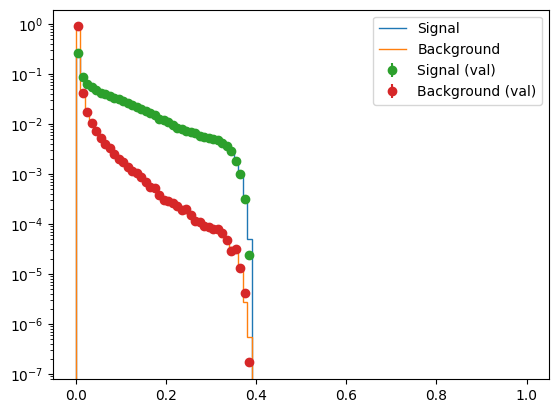

In [11]:
fig, ax = plt.subplots()
ax.stairs(values=h_sig_train.view(), edges=h_sig_train.axes[0].edges, label="Signal")
ax.stairs(values=h_bkg_train.view(), edges=h_bkg_train.axes[0].edges, label="Background")

ax.errorbar(h_sig_val.axes[0].centers, h_sig_val.view(), yerr=0, 
            fmt='o', label="Signal (val)")
ax.errorbar(h_bkg_val.axes[0].centers, h_bkg_val.view(), yerr=0, 
            fmt='o', label="Background (val)")

ax.set_yscale('log')
plt.legend()
plt.show()